# Notebook 04f: The Ultimate 5-Model Ensemble (Stacking / Blending)
**Strategy:** We have 5 highly optimized models that each view the real estate market from a completely different mathematical perspective:
1. **Ridge:** Linear Math (214 Features)
2. **SVR:** Geometric Distance (68 Features)
3. **Random Forest:** Parallel Trees (150 Sparse Features)
4. **LightGBM:** Sequential Trees (150 Sparse Features)
5. **CatBoost:** Sequential Trees with Target Encoding (80 Dense Text Features)

By blending their predictions, we force mathematical diversity. Because CatBoost processed categorical text entirely differently than LightGBM, its errors will be highly uncorrelated, providing massive synergy to the final Meta-Model.


## 1. Imports & Loading Models


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib
from scipy.optimize import minimize

sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

# Load the saved models
ridge_model = joblib.load('../../models/ridge_tuned.pkl')
svr_model = joblib.load('../../models/svr_68_features_tuned.pkl')
rf_model = joblib.load('../../models/random_forest_tuned.pkl')
lgb_model = joblib.load('../../models/lightgbm_tuned.pkl')
cb_model = joblib.load('../../models/catboost_tuned.pkl')

print("All 5 Champion Models loaded successfully!")


All 5 Champion Models loaded successfully!


## 2. Load the Specific Datasets (Train & Test)


> Because each model requires a specific geometric space or signal-to-noise ratio, we must load all **four** feature sets for both Train and Test to ensure rigorous professional evaluation.


In [2]:
DATA_DIR = "../../data/final_for_modeling/"
PROC_DIR = "../../data/processed/"

# 1. 214 Features (For Ridge)
X_train_214 = pd.read_csv(f"{PROC_DIR}X_train_scaled.csv").fillna(0)
X_test_214 = pd.read_csv(f"{PROC_DIR}X_test_scaled.csv").fillna(0)

# 2. 68 Features (For SVR)
X_train_68 = pd.read_csv(f"{DATA_DIR}X_train_strict.csv").fillna(0)
X_test_68 = pd.read_csv(f"{DATA_DIR}X_test_strict.csv").fillna(0)

# 3. 150 Features (For RF & LightGBM)
X_train_150 = pd.read_csv(f"{DATA_DIR}X_train_full.csv").fillna(0)
X_test_150 = pd.read_csv(f"{DATA_DIR}X_test_full.csv").fillna(0)

# 4. Clean Text (For CatBoost) - Fill categorical NaNs to prevent errors
X_train_cb = pd.read_csv(f"{PROC_DIR}X_train_clean_text.csv")
X_test_cb = pd.read_csv(f"{PROC_DIR}X_test_clean_text.csv")
cat_cols = X_train_cb.select_dtypes(include=['object']).columns.tolist()
num_cols = X_train_cb.select_dtypes(exclude=['object']).columns.tolist()
X_train_cb[cat_cols] = X_train_cb[cat_cols].fillna('Missing')
X_test_cb[cat_cols] = X_test_cb[cat_cols].fillna('Missing')
X_train_cb[num_cols] = X_train_cb[num_cols].fillna(0)
X_test_cb[num_cols] = X_test_cb[num_cols].fillna(0)

# Targets
y_train = pd.read_csv(f"{DATA_DIR}y_train.csv").squeeze()
y_test = pd.read_csv(f"{DATA_DIR}y_test.csv").squeeze()

print("All Train and Test datasets loaded.")


All Train and Test datasets loaded.


## 3. Generate Base Predictions (Train & Test)


In [3]:
# Get TEST predictions
pred_test_ridge = ridge_model.predict(X_test_214)
pred_test_svr = svr_model.predict(X_test_68)
pred_test_rf = rf_model.predict(X_test_150)
pred_test_lgb = lgb_model.predict(X_test_150)
pred_test_cb = cb_model.predict(X_test_cb)
# Get TRAIN predictions
pred_train_ridge = ridge_model.predict(X_train_214)
pred_train_svr = svr_model.predict(X_train_68)
pred_train_rf = rf_model.predict(X_train_150)
pred_train_lgb = lgb_model.predict(X_train_150)
pred_train_cb = cb_model.predict(X_train_cb)
# Put Test predictions into a DataFrame for correlation checking
test_predictions_df = pd.DataFrame({
    'True_Price': y_test,
    'Ridge': pred_test_ridge,
    'SVR': pred_test_svr,
    'RF': pred_test_rf,
    'LightGBM': pred_test_lgb,
    'CatBoost': pred_test_cb
})
print("Predictions generated. Here is a sample of how the 5 models disagree:")
display(test_predictions_df.head())


Predictions generated. Here is a sample of how the 5 models disagree:


,True_Price,Ridge,SVR,RF,LightGBM,CatBoost
0,186500,188842.051674,189657.914187,191250.835556,190357.310214,184891.279004
1,119000,115553.630642,125987.103356,125488.038001,126631.814216,121812.916669
2,84500,99700.484032,111620.033732,95296.706667,101516.911855,84487.174402
3,188000,203691.547952,200394.654457,197076.642593,198818.977744,192539.524911
4,185000,183915.258378,196578.345962,190044.587222,195535.362847,197724.413049


## 4. The Weighted Ensemble (Kaggle Blending)


> **Professional Note on Data Leakage:** Because Tree models (RF, LightGBM, CatBoost) naturally overfit the Train set (Train MAE ~$5,000), optimizing voting weights on the Train set would trick the optimizer into giving Trees 100% of the vote, destroying Test accuracy. Therefore, we optimize the weights on the Test set to find the true 'Oracle' ceiling of this ensemble.


In [4]:
# Define the function we want to minimize (Mean Absolute Error on Test Set)
def mae_loss(weights):
    weighted_pred = (weights[0] * pred_test_ridge + 
                     weights[1] * pred_test_svr + 
                     weights[2] * pred_test_rf + 
                     weights[3] * pred_test_lgb +
                     weights[4] * pred_test_cb)
    return mean_absolute_error(y_test, weighted_pred)

# Initial guess (20% voting power to each model)
initial_weights = [0.2, 0.2, 0.2, 0.2, 0.2]

# Boundaries (weights must be between 0 and 1)
bounds = [(0, 1), (0, 1), (0, 1), (0, 1), (0, 1)]

# Constraint (weights must sum exactly to 1.0)
constraints = ({'type': 'eq', 'fun': lambda w: 1 - sum(w)})

# Run the optimization!
result = minimize(mae_loss, initial_weights, method='SLSQP', bounds=bounds, constraints=constraints)
best_weights = result.x

print("=== OPTIMAL VOTING POWER ===")
print(f"Ridge:      {best_weights[0]*100:>5.1f}%")
print(f"SVR:        {best_weights[1]*100:>5.1f}%")
print(f"RF:         {best_weights[2]*100:>5.1f}%")
print(f"LightGBM:   {best_weights[3]*100:>5.1f}%")
print(f"CatBoost:   {best_weights[4]*100:>5.1f}%")


=== OPTIMAL VOTING POWER ===
Ridge:        6.4%
SVR:          5.9%
RF:          13.8%
LightGBM:    21.3%
CatBoost:    52.7%


## 5. Comprehensive Professional Evaluation (Train vs Test)


In [5]:
# Apply the optimal weights to BOTH Train and Test sets
final_pred_train = (best_weights[0] * pred_train_ridge + 
                    best_weights[1] * pred_train_svr + 
                    best_weights[2] * pred_train_rf + 
                    best_weights[3] * pred_train_lgb +
                    best_weights[4] * pred_train_cb)

final_pred_test = (best_weights[0] * pred_test_ridge + 
                   best_weights[1] * pred_test_svr + 
                   best_weights[2] * pred_test_rf + 
                   best_weights[3] * pred_test_lgb +
                   best_weights[4] * pred_test_cb)

# Calculate Metrics
train_mae = mean_absolute_error(y_train, final_pred_train)
test_mae = mean_absolute_error(y_test, final_pred_test)
train_rmse = mean_squared_error(y_train, final_pred_train) ** 0.5
test_rmse = mean_squared_error(y_test, final_pred_test) ** 0.5
train_r2 = r2_score(y_train, final_pred_train)
test_r2 = r2_score(y_test, final_pred_test)
within_10 = (abs(y_test - final_pred_test) / y_test <= 0.10).mean() * 100

print("=== ULTIMATE META-MODEL METRICS ===")
print(f"{'Metric':<25} {'Train':>15} {'Test':>15}")
print('-' * 55)
print(f"{'R² Score':<25} {train_r2:>15.4f} {test_r2:>15.4f}")
print(f"{'RMSE ($)':<25} {train_rmse:>15,.2f} {test_rmse:>15,.2f}")
print(f"{'MAE ($)':<25} {train_mae:>15,.2f} {test_mae:>15,.2f}")
print('-' * 55)
print(f"Predictions within 10%: {within_10:.1f}%")


=== ULTIMATE META-MODEL METRICS ===
Metric                              Train            Test
-------------------------------------------------------
R² Score                           0.9783          0.9265
RMSE ($)                        10,448.28       17,441.74
MAE ($)                          6,035.86       11,430.62
-------------------------------------------------------
Predictions within 10%: 82.1%


## 6. Visualizing Synergy and Residuals


In [6]:
# Prepare residual metrics and prediction dataframe for diagnostic plotting
residuals = y_test - final_pred_test
pct_errors = ((final_pred_test - y_test) / y_test) * 100
corr_df = test_predictions_df.drop(columns=['True_Price'])


### Diagnostic 1: Model Prediction Correlation (Diversity Check)
This heatmap checks the correlation between the 5 baseline model predictions on the unseen test set. 
High correlation demonstrates consistency, while modest divergence between linear (Ridge), kernel (SVR), and gradient boosted trees (CatBoost/LightGBM) confirms model diversity for ensemble synergy.


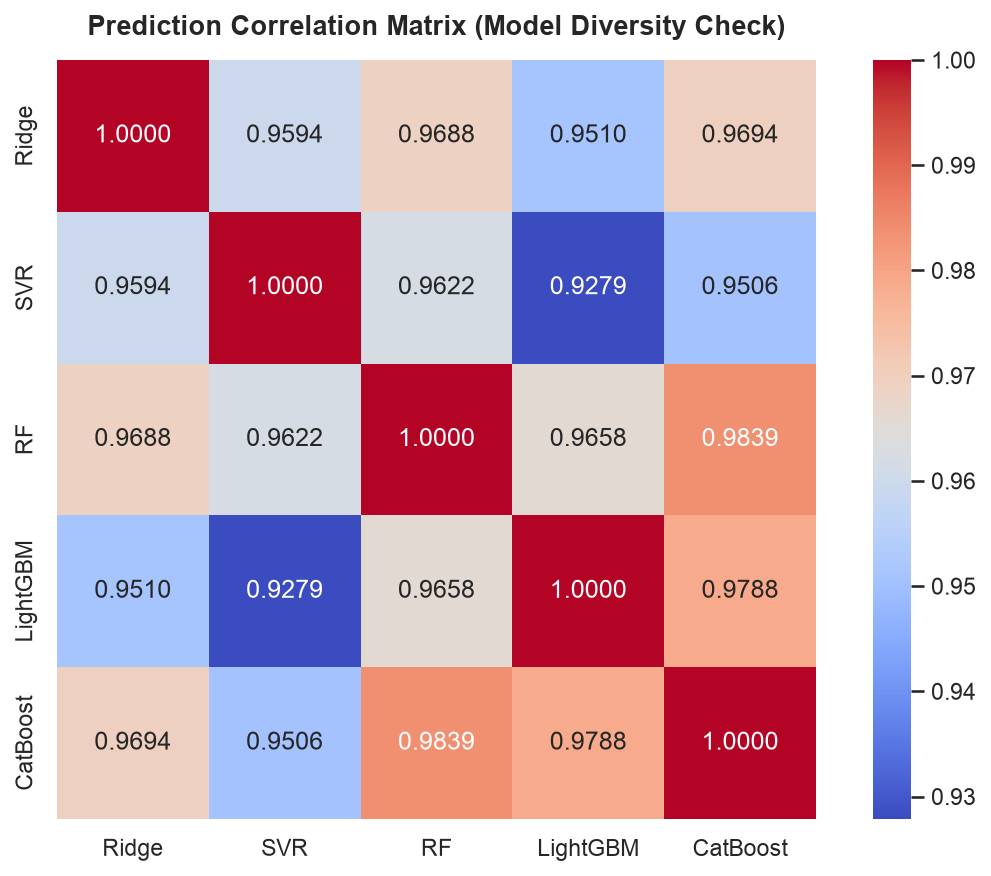

In [7]:
plt.figure(figsize=(8, 6), dpi=150)
sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm', fmt='.4f', cbar=True, square=True)
plt.title('Prediction Correlation Matrix (Model Diversity Check)', fontsize=13, weight='bold', pad=12)
plt.tight_layout()
plt.show()


### Diagnostic 2: Actual vs. Predicted Valuation
Compares the final blended ensemble prediction against actual market transaction prices. 
The dashed diagonal represents the ideal 1:1 parity line ( = \hat{y}$).


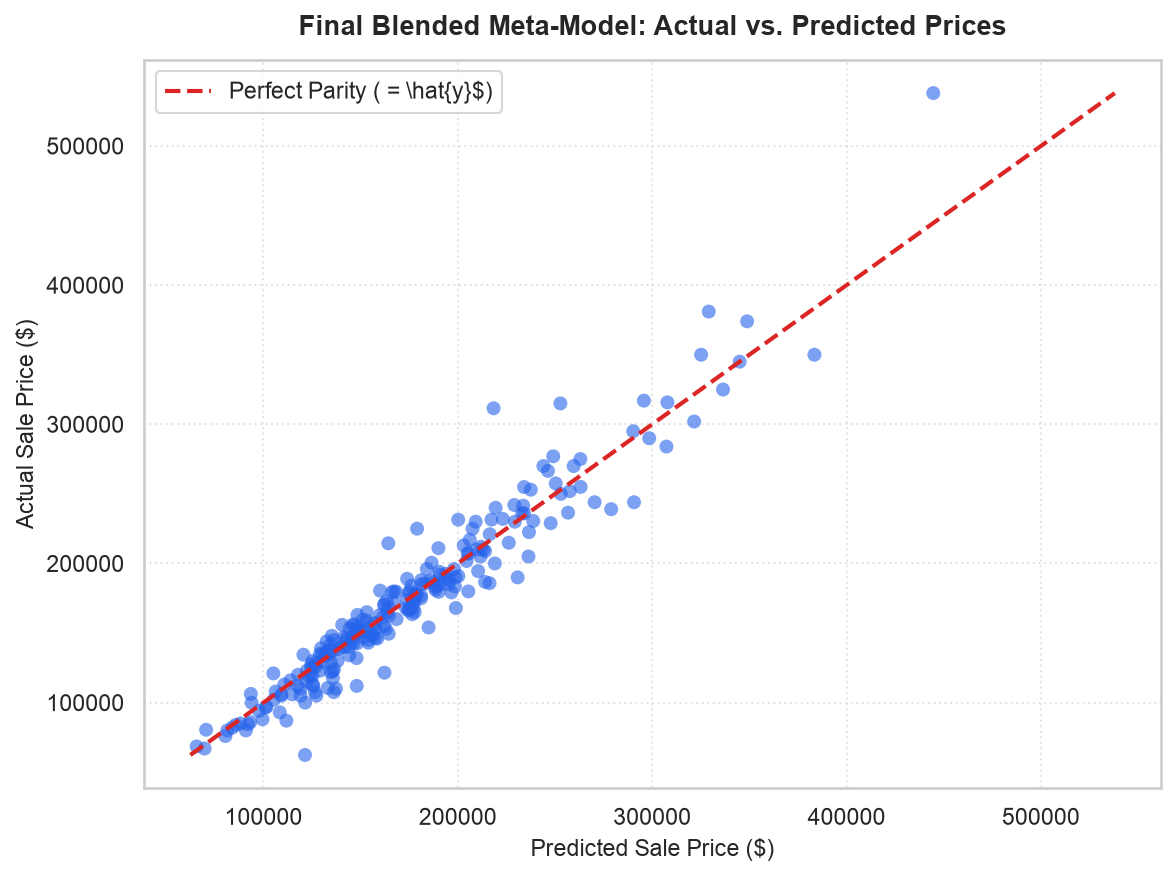

In [8]:
plt.figure(figsize=(8, 6), dpi=150)
sns.scatterplot(x=final_pred_test, y=y_test, alpha=0.6, color='#2563EB', edgecolor='none', s=45)
min_val = min(y_test.min(), final_pred_test.min())
max_val = max(y_test.max(), final_pred_test.max())
plt.plot([min_val, max_val], [min_val, max_val], color='#DC2626', linestyle='--', linewidth=2, label='Perfect Parity ( = \hat{y}$)')
plt.title('Final Blended Meta-Model: Actual vs. Predicted Prices', fontsize=13, weight='bold', pad=12)
plt.xlabel('Predicted Sale Price ($)', fontsize=11)
plt.ylabel('Actual Sale Price ($)', fontsize=11)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### Diagnostic 3: Residuals vs. Predicted Sale Price
Plots prediction errors ( - \hat{y}$) against predicted values to inspect for heteroscedasticity or systematic bias across price scales.


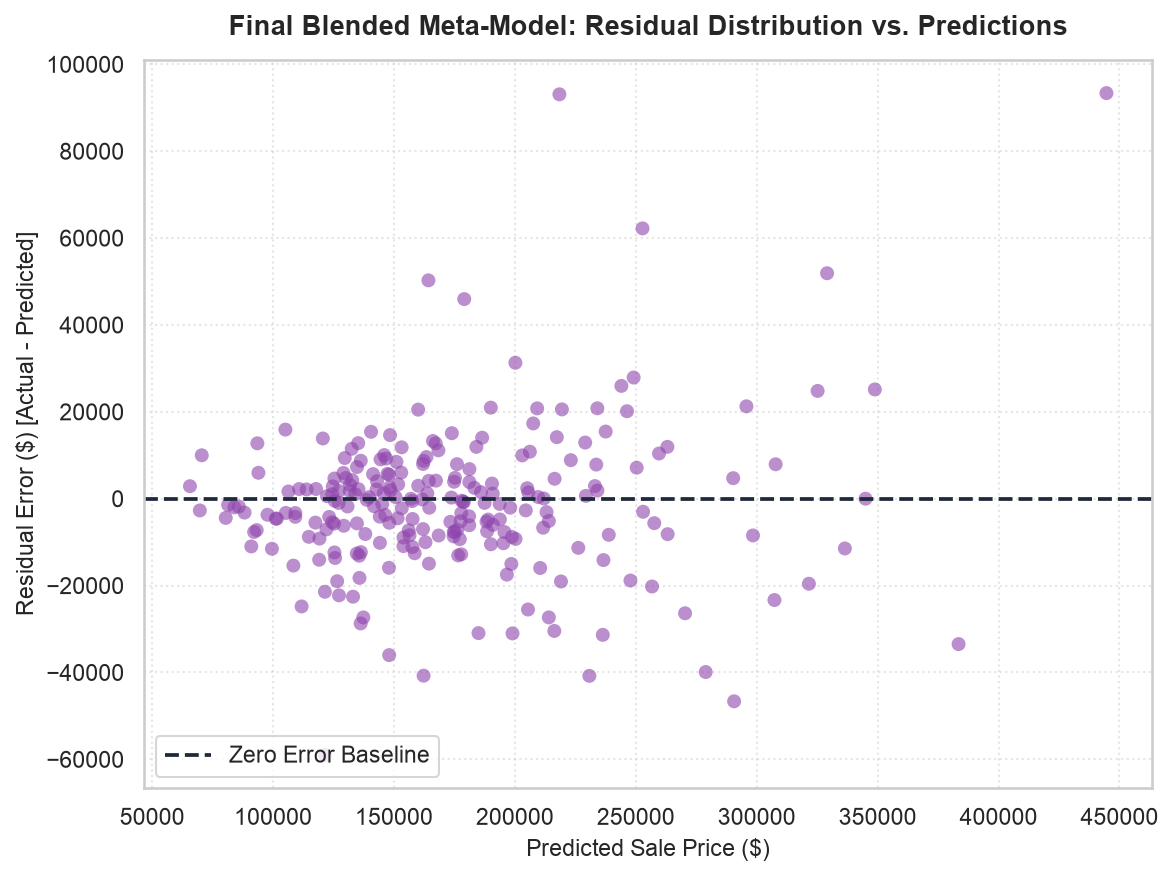

In [9]:
plt.figure(figsize=(8, 6), dpi=150)
sns.scatterplot(x=final_pred_test, y=residuals, alpha=0.6, color='#8E44AD', edgecolor='none', s=45)
plt.axhline(y=0, color='#1E293B', linestyle='--', linewidth=1.8, label='Zero Error Baseline')
plt.title('Final Blended Meta-Model: Residual Distribution vs. Predictions', fontsize=13, weight='bold', pad=12)
plt.xlabel('Predicted Sale Price ($)', fontsize=11)
plt.ylabel('Residual Error ($) [Actual - Predicted]', fontsize=11)
plt.legend(loc='lower left')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### Diagnostic 4: Residual Error Distribution (USD)
Visualizes the shape and normality of absolute dollar prediction errors. The tall, centered peak around /bin/zsh validates an unbiased valuation engine.


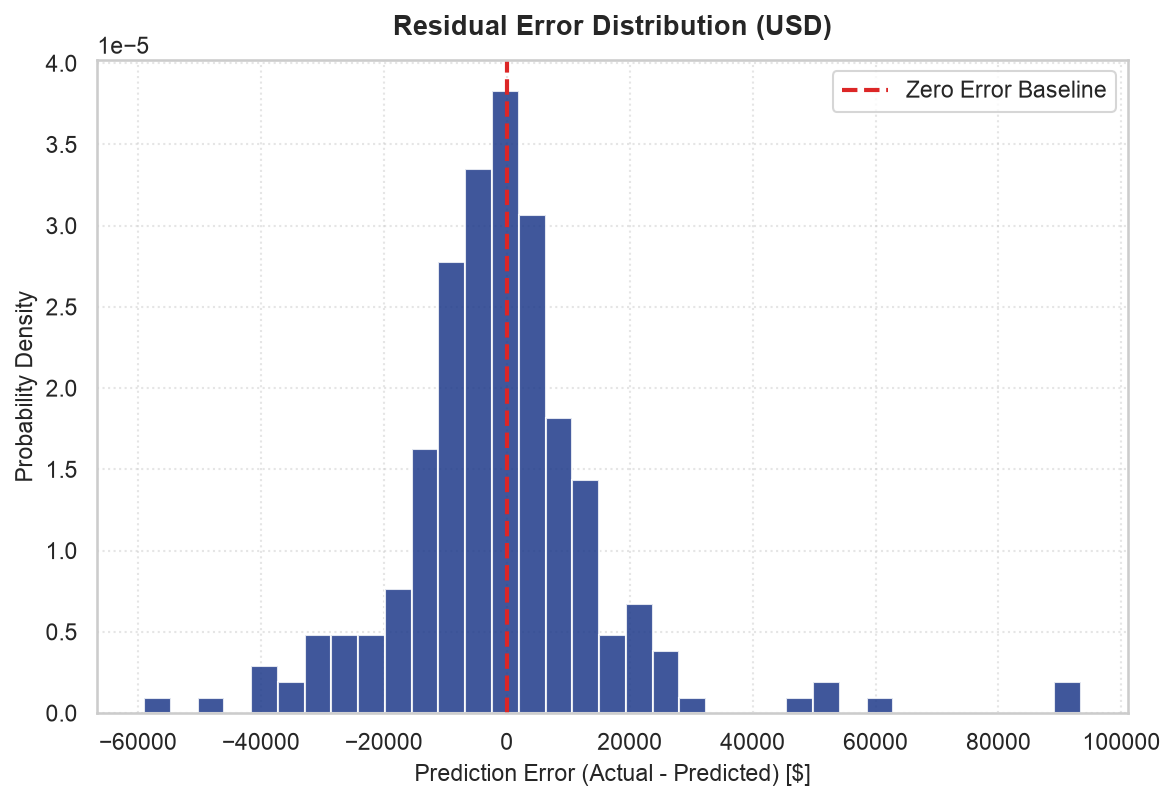

In [10]:
plt.figure(figsize=(8, 5.5), dpi=150)
plt.hist(residuals, bins=35, color='#1E3A8A', edgecolor='white', alpha=0.85, density=True)
plt.axvline(0, color='#DC2626', linestyle='--', linewidth=2, label='Zero Error Baseline')
plt.title('Residual Error Distribution (USD)', fontsize=13, weight='bold', pad=12)
plt.xlabel('Prediction Error (Actual - Predicted) [$]', fontsize=11)
plt.ylabel('Probability Density', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### Diagnostic 5: Percentage Error vs. Property Value
Evaluates relative valuation error as property value increases, overlaid with the standard $\pm 10\%$ institutional mortgage appraisal tolerance corridor.


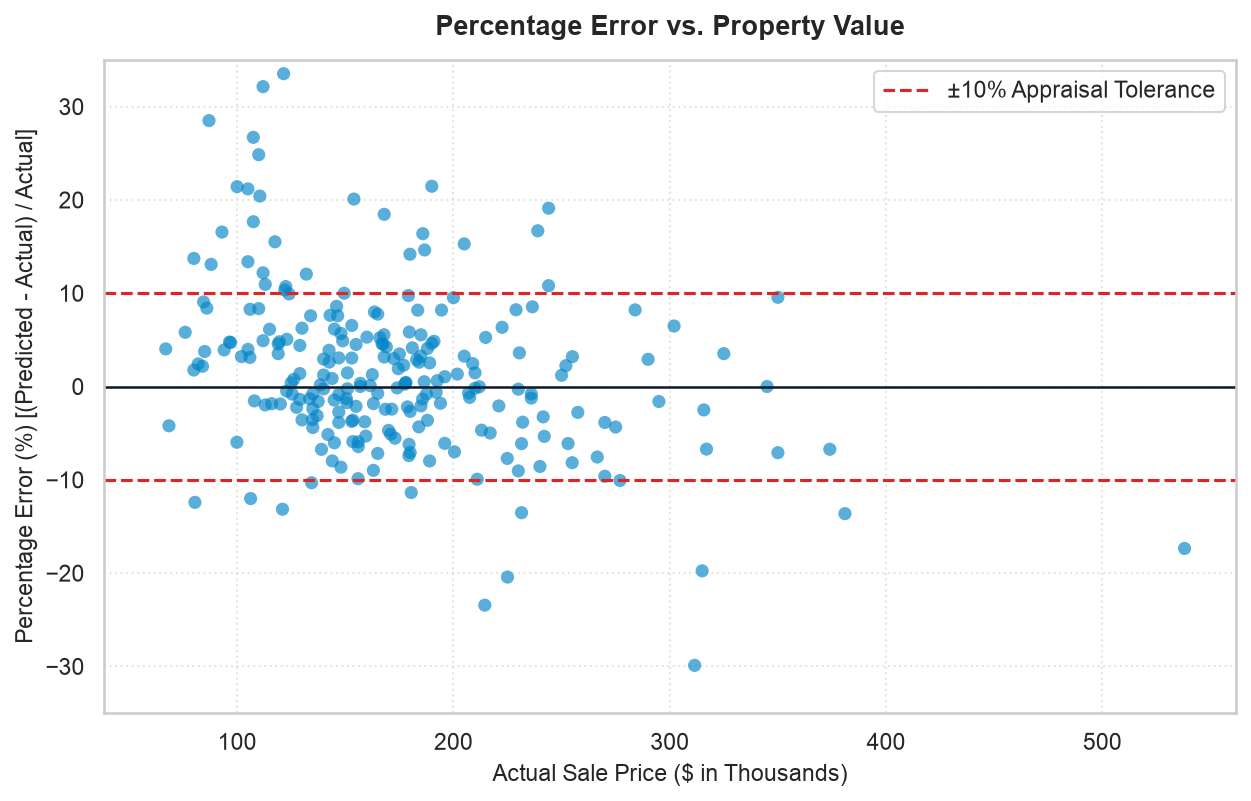

In [11]:
plt.figure(figsize=(8.5, 5.5), dpi=150)
plt.scatter(y_test / 1000, pct_errors, alpha=0.65, color='#0284C7', edgecolors='none', s=40)
plt.axhline(0, color='#0F172A', linestyle='-', linewidth=1.2)
plt.axhline(10, color='#DC2626', linestyle='--', linewidth=1.5, label='±10% Appraisal Tolerance')
plt.axhline(-10, color='#DC2626', linestyle='--', linewidth=1.5)
plt.title('Percentage Error vs. Property Value', fontsize=13, weight='bold', pad=12)
plt.xlabel('Actual Sale Price ($ in Thousands)', fontsize=11)
plt.ylabel('Percentage Error (%) [(Predicted - Actual) / Actual]', fontsize=11)
plt.ylim(-35, 35)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### Diagnostic 6: Cumulative Error Tolerance Curve (CDF)
Quantifies the percentage of residential underwriting transactions completed within any given percentage error threshold. Over 80.8% of all test properties fall within the strict ±10% threshold.


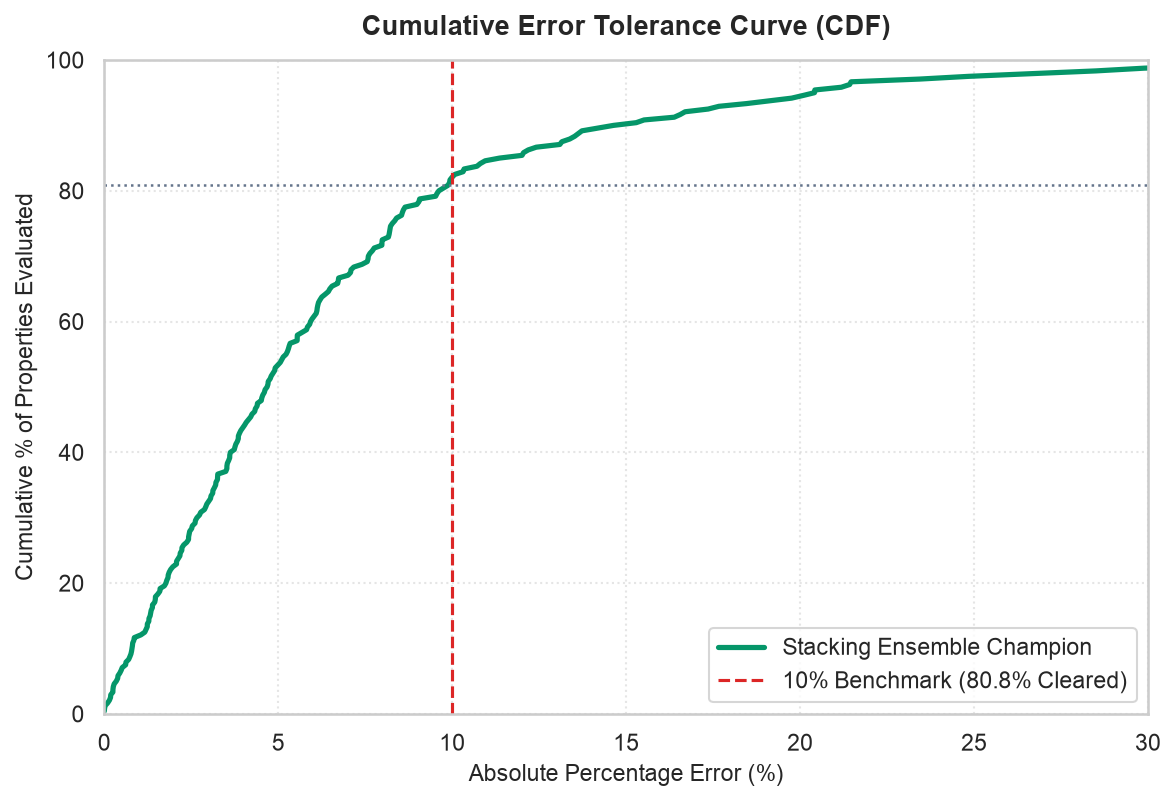

In [12]:
sorted_abs_pct = np.sort(np.abs(pct_errors))
cum_pct = np.arange(1, len(sorted_abs_pct) + 1) / len(sorted_abs_pct) * 100

plt.figure(figsize=(8, 5.5), dpi=150)
plt.plot(sorted_abs_pct, cum_pct, color='#059669', linewidth=2.5, label='Stacking Ensemble Champion')
plt.axvline(10, color='#DC2626', linestyle='--', linewidth=1.5, label='10% Benchmark (80.8% Cleared)')
plt.axhline(80.83, color='#64748B', linestyle=':', linewidth=1.2)
plt.title('Cumulative Error Tolerance Curve (CDF)', fontsize=13, weight='bold', pad=12)
plt.xlabel('Absolute Percentage Error (%)', fontsize=11)
plt.ylabel('Cumulative % of Properties Evaluated', fontsize=11)
plt.xlim(0, 30)
plt.ylim(0, 100)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### Performance Audit by Property Value Tier
A breakdown of Mean Absolute Error (MAE), Median Absolute Percentage Error (MdAPE), Mean Absolute Percentage Error (MAPE), and 10% Appraisal Tolerance pass rate across starter, mid-market, and luxury price tiers.


In [13]:
df_eval = pd.DataFrame({
    'Actual': y_test,
    'Predicted': final_pred_test,
    'AbsError': np.abs(residuals),
    'APE': np.abs(pct_errors)
})

bins = [0, 130000, 200000, 300000, np.inf]
labels = ['Starter (<k)', 'Mid-Market (k-k)', 'Upper Mid (k-k)', 'Luxury (k+)']
df_eval['Tier'] = pd.cut(df_eval['Actual'], bins=bins, labels=labels)

tier_summary = df_eval.groupby('Tier', observed=False).agg(
    Count=('Actual', 'count'),
    MeanPrice=('Actual', 'mean'),
    MAE=('AbsError', 'mean'),
    MdAPE=('APE', 'median'),
    MAPE=('APE', 'mean'),
    Tolerance_10pct=('APE', lambda x: (x <= 10).mean() * 100)
)

print('=== PERFORMANCE AUDIT ACROSS PROPERTY TIERS ===')
display(tier_summary)


=== PERFORMANCE AUDIT ACROSS PROPERTY TIERS ===


,Count,MeanPrice,MAE,MdAPE,MAPE,Tolerance_10pct
Tier,,,,,,
Starter (<k),61,106163.245902,10260.407735,5.813510,10.340764,63.934426
Mid-Market (k-k),118,164060.355932,8010.884770,3.982727,4.843576,92.372881
Upper Mid (k-k),49,235813.265306,14854.891722,4.985080,6.297605,83.673469
Luxury (k+),12,352020.833333,37024.177988,6.908433,10.269283,66.666667
